In [19]:
import numpy as np
import qiskit
import openfermion
import pyscf

# Lanczos algorithm and subspace expansion

The Lanczos method builds a Krylov subspace by repeatedly applying the Hamiltonian to a reference state. In the quantum computing context, we can generate basis states by applying time evolution operators $e^{-iHt}$ at different times. The overlap matrix $S_{ij} = \langle\psi_i|\psi_j\rangle$ and Hamiltonian matrix $H_{ij} = \langle\psi_i|H|\psi_j\rangle$ are then computed, and the generalized eigenvalue problem $H\mathbf{c} = ES\mathbf{c}$ yields approximate eigenvalues.

In [20]:
# H4 molecule
from pyscf import gto, scf

# Build molecule
d=2.0
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 1*d)],
          ["H", (0.0, 0.0, 2*d)],
          ["H", (0.0, 0.0, 3*d)]
          ],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.57561647670187


np.float64(-1.575616476701867)

In [21]:
from pyscf import fci

# singlets only
cisolver = fci.FCI(mol, mf.mo_coeff)
fci_energy, ci = cisolver.kernel()
print("FCI energy:", fci_energy)

FCI energy: -1.897780645989874


In [22]:
tol_ampl = 0.01

from pyscf.fci import cistring
mc = cisolver

ncas = mc.norb
nelec = mc.nelec

# determinants α i β (representats com enters amb bits d’ocupació)
na, nb = nelec
alpha_det = cistring.make_strings(range(ncas), na)
beta_det = cistring.make_strings(range(ncas), nb)


def interleave_bits(a, b, ncas):
    """Return interleaved occupation string (αβ αβ ...)"""
    a_bits = [(a >> i) & 1 for i in range(ncas)]
    b_bits = [(b >> i) & 1 for i in range(ncas)]
    inter = []
    for i in reversed(range(ncas)):
        inter.append(str(a_bits[i]))
        inter.append(str(b_bits[i]))
    return ''.join(inter)[::-1]

print('\namplitudes FCI')
for i, a in enumerate(alpha_det):
    for j, b in enumerate(beta_det):
        amp = mc.ci[i, j]
        if amp**2 > tol_ampl:
            # print(f"α={format(a, f'0{ncas}b')}  β={format(b, f'0{ncas}b')}  coef={amp:+.6f}")
            cfg = interleave_bits(a, b, ncas)
            print(f"{cfg}   {amp:+.6f}  ({amp**2:.6f}) ")


amplitudes FCI
11110000   +0.694100  (0.481775) 
11001100   -0.388924  (0.151262) 
01100110   -0.181096  (0.032796) 
00111100   -0.114150  (0.013030) 
10010110   -0.255203  (0.065128) 
01101001   -0.255203  (0.065128) 
11000011   -0.107524  (0.011561) 
10011001   -0.181096  (0.032796) 
00110011   -0.251266  (0.063134) 
00001111   +0.259514  (0.067347) 


## Exact reference state

The FCI calculation provides the exact ground-state energy and wavefunction in the given basis. The dominant determinants and their amplitudes reveal the structure of the correlated state. These results serve as the benchmark for the Lanczos subspace expansion method.

In [23]:
from openfermion import FermionOperator, hermitian_conjugated
te_oper = 1.0 * (FermionOperator('5^ 4^ 3 2 ') + FermionOperator('6^ 5^ 2 1 '))
te_oper = te_oper + hermitian_conjugated(te_oper)
print(te_oper)

1.0 [1^ 2^ 5 6] +
1.0 [2^ 3^ 4 5] +
1.0 [5^ 4^ 3 2] +
1.0 [6^ 5^ 2 1]


In [24]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

e_nuc = mf.energy_nuc()

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)
# nuclear
print(e_nuc)

[[-1.13379714e+00 -4.09394740e-16  9.24693961e-02 -1.11022302e-16]
 [-4.57966998e-16 -1.04226825e+00 -5.55111512e-16 -7.41977398e-02]
 [ 9.24693961e-02 -5.55111512e-16 -9.78602165e-01 -4.16333634e-16]
 [-1.66533454e-16 -7.41977398e-02 -3.95516953e-16 -9.67108698e-01]]
[[[[ 3.50481811e-01 -2.25514052e-17 -5.76182543e-02  9.02056208e-17]
   [-3.46944695e-18  1.64643593e-01 -6.93889390e-18  3.03991509e-02]
   [-5.76182543e-02 -1.38777878e-17  1.27781482e-01  1.52655666e-16]
   [ 8.32667268e-17  3.03991509e-02  1.45716772e-16  1.23346862e-01]]

  [[-3.46944695e-18  1.64643593e-01 -6.93889390e-18  3.03991509e-02]
   [ 3.19106671e-01  2.15105711e-16  1.74272684e-02  2.08166817e-17]
   [ 1.38777878e-16  6.97056778e-02 -3.23525928e-16 -1.03951062e-01]
   [ 5.98408006e-02 -2.77555756e-17 -1.29023423e-01  2.53269627e-16]]

  [[-5.76182543e-02 -1.38777878e-17  1.27781482e-01  1.52655666e-16]
   [ 1.38777878e-16  6.97056778e-02 -3.23525928e-16 -1.03951062e-01]
   [ 3.22145549e-01 -3.88578059e-16  

In [25]:
from openfermion import InteractionOperator, jordan_wigner
from openfermion.chem.molecular_data import spinorb_from_spatial

h1_so, eri_so = spinorb_from_spatial(h1_mo, eri_mo)
hamiltonian = InteractionOperator(e_nuc, h1_so, 0.5*eri_so)

In [26]:
from openfermion import normal_ordered, get_fermion_operator
def is_hermitian(op):
    hermitian_part = normal_ordered(op - hermitian_conjugated(op))
    return len(hermitian_part.terms) == 0

print('is hermitian?')
print('Hamiltonian : ', is_hermitian(get_fermion_operator(hamiltonian)))
print('te_oper     : ', is_hermitian(te_oper))

is hermitian?
Hamiltonian :  True
te_oper     :  True


## Molecular Hamiltonian

The molecular integrals are transformed to spin-orbital form and assembled into a second-quantized Hamiltonian. The Jordan-Wigner transformation maps fermionic operators to qubit operators, enabling quantum circuit implementation. The Hamiltonian is Hermitian, guaranteeing real eigenvalues.

In [27]:
from openfermion import FermionOperator
# a b a b a b
state = FermionOperator('0^ 1^ 2^ 3^')

In [28]:
from openfermion import get_sparse_operator, jordan_wigner
from scipy.sparse.linalg import expm, expm_multiply
ha_qubit = jordan_wigner(hamiltonian)

def time_evolution_trotter(t):
    vec = get_sparse_operator(state, n_qubits=8)
    for op in ha_qubit.get_operators():
        sparse_op =-1j*t * get_sparse_operator(op, n_qubits=8)
        vec = expm_multiply(sparse_op, vec)
    return vec

## Time evolution and Krylov subspace

The Lanczos method generates basis states by applying the time evolution operator $e^{-iHt}$ at different times. The Trotter approximation decomposes the exponential into a product of simpler terms. States at different times form a Krylov subspace that approximates the low-energy eigenspace of the Hamiltonian.

In [29]:
dt = 1

In [30]:
sparse_h = get_sparse_operator(ha_qubit, n_qubits=8)

def get_hamiltonian_matrix(n_dim):
    s_matrix = np.identity(n_dim, dtype=complex)
    h_matrix = np.identity(n_dim, dtype=complex)

    for i in range(n_dim):
        for j in range(i, n_dim):

            bra = time_evolution_trotter(i*dt).transpose().conj()
            ket = time_evolution_trotter(j*dt)

            s_matrix[i, j] = (bra @ ket)[0, 0]
            h_matrix[i, j] = (bra @ sparse_h @ ket)[0, 0]

            s_matrix[j, i] = s_matrix[i, j].conj()
            h_matrix[j, i] = h_matrix[i, j].conj()

    return h_matrix, s_matrix


### Regularization matrices

By constructing the Hamiltonian matrix using a non-orthogonal basis it is likely to encouter singulariy-matrix problems at the diagonalization. To avoid this it useful to regularize the matrix by removing redundant states

In [31]:
def get_regularized_matrices(h_matrix, s_matrix, threshold=1e-6):

    # Congruence transformation (Lowdin method)
    eigvals, eigvecs = np.linalg.eigh(s_matrix)
    # print('eigvals: ', eigvals)
    # Apply threshold to eigenvalues to avoid numerical instability
    idx = eigvals > threshold
    S_inv_sqrt = eigvecs[:, idx] @ np.diag(eigvals[idx] ** -0.5) @ eigvecs[:, idx].T
    # print('shape_S_inv: ', eigvecs[:, idx].shape)

    # Transform the tensor to the orthonormal basis
    h_eff = S_inv_sqrt.conj().T @ h_matrix @ S_inv_sqrt
    s_eff = S_inv_sqrt.conj().T @ s_matrix @ S_inv_sqrt

    return h_eff, s_eff


### Effective rank check
The analysis of the actual rank of the spanned Hilbert space by the obtained basis states can be useful to evaluate the quality of the algorithm in generating good basis states.

In [32]:
def effective_rank(matrix, threshold=1e-12):

    eigvals = np.linalg.eigvalsh(matrix)
    eigvals = eigvals[eigvals > threshold]

    p = eigvals / np.sum(eigvals)
    entropy = -np.sum(p * np.log(p))

    return np.exp(entropy)


## Subspace expansion and convergence

The Lanczos algorithm builds matrices $H_{ij}$ and $S_{ij}$ in the time-evolved basis. The generalized eigenvalue problem $H\mathbf{c} = ES\mathbf{c}$ yields approximate energies. As the subspace dimension increases, the lowest eigenvalue converges toward the exact ground-state energy. The effective rank measures the numerical stability of the overlap matrix.

Converged energy:  -1.888340654515004


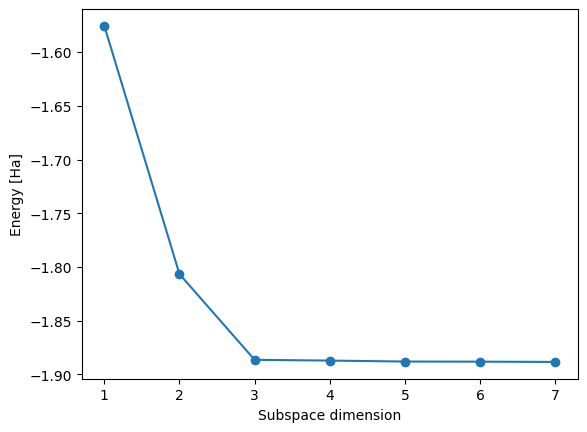

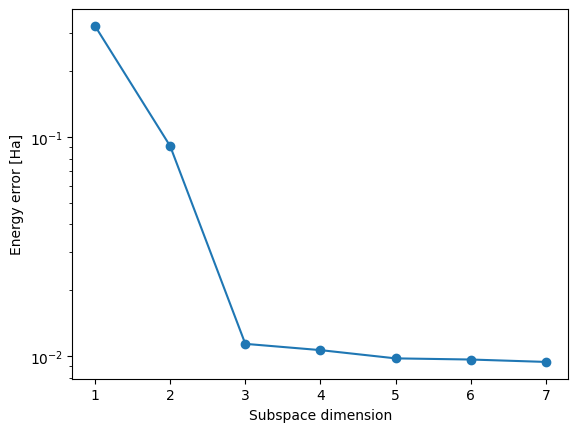

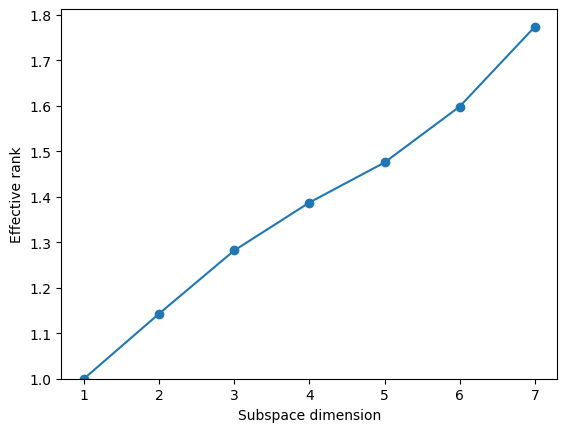

In [33]:
from scipy.linalg import eigvals
import matplotlib.pyplot as plt

energies = []
errors = []
ranks = []
dims = []
for n_dim in range(1, 8):
    h_matrix, s_matrix = get_hamiltonian_matrix(n_dim)

    ranks.append(effective_rank(s_matrix))

    h_matrix, s_matrix = get_regularized_matrices(h_matrix, s_matrix)
    vals = min(eigvals(h_matrix, s_matrix))
    energies.append(vals.real)
    errors.append(vals.real - fci_energy)
    dims.append(n_dim)

print('Converged energy: ', energies[-1])
plt.plot(dims, energies, '-o')
plt.xlabel('Subspace dimension')
plt.ylabel('Energy [Ha]')
plt.show()

plt.plot(dims, errors, '-o')
plt.yscale('log')
plt.xlabel('Subspace dimension')
plt.ylabel('Energy error [Ha]')
plt.show()

plt.plot(dims, ranks, '-o')
plt.xlabel('Subspace dimension')
plt.ylabel('Effective rank')
plt.ylim(1, None)
plt.show()

## Quantum circuit for time evolution

The circuit implements the Trotterized time evolution operator. Each Pauli term in the Jordan-Wigner Hamiltonian is exponentiated using basis rotations, CNOT ladders, and RZ gates. The parameter $\theta$ controls the evolution time. This circuit prepares states in the Krylov subspace for the Hadamard test measurements.

In [16]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# redefine generator for time evolution
# te_qubit = jordan_wigner(-1j * hamiltonian)
te_qubit = jordan_wigner(-1j * te_oper)

qc = QuantumCircuit(2)
# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc = QuantumCircuit(8)


# reference state
qc.x(0)
qc.x(1)
qc.x(2)
qc.x(3)


for op, coef in te_qubit.terms.items():

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    for qubit, pauli in op[1:]:
        qc.cx(qubit, op[0][0])

    if len(op) > 0:
        qc.rz(2*theta * coef.imag, op[0][0])

    for qubit, pauli in op[1:]:
        qc.cx(qubit, op[0][0])

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(-np.pi / 2, [qubit])

    #qc.barrier()

print('deph:', qc.depth())
#qc.draw('mpl')

deph: 145


## Measuring matrix elements with Hadamard test

The Hadamard test estimates matrix elements $\langle\psi_i|O|\psi_j\rangle$ using an ancilla qubit. The ancilla controls whether the operator $O$ is applied between the two states. Measuring the ancilla's expectation value gives the real or imaginary part of the matrix element, depending on the phase gate. This enables quantum computation of the Lanczos matrices without full state tomography.

In [17]:
from qiskit.primitives import StatevectorSampler


def get_matrix_element(circuit_state_1, circuit_state_2, operator, imaginary_part):


    n_qubits = circuit_state_1.num_qubits

    total_energy = 0
    total_variance = 0


    for op, coefficient in operator.terms.items():

        U_circ = qiskit.QuantumCircuit(n_qubits)

        definition = [index for index in range(n_qubits)]
        U_circ.append(circuit_state_1.to_gate(label="U_1"), definition)

        for qi, pauli in op:
            if pauli == "X":
                U_circ.x([qi])
            if pauli == "Y":
                U_circ.y([qi])
            if pauli == "Z":
                U_circ.z([qi])

        # Initialize circuit 2

        U_circ.append(circuit_state_2.to_gate(label="U_2^dagger").inverse(), definition)

        U_controlled_gate = (U_circ.to_gate(label="U")).control(1)

        # Build Hadamard test circuit
        from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

        anc = QuantumRegister(1, 'ancilla')
        q = QuantumRegister(n_qubits, 'qubit')
        c_reg = ClassicalRegister(1, "meas")

        # build Hadamard test circuit
        circ_Hadamard = QuantumCircuit(anc, q, c_reg)

        circ_Hadamard.h(anc[0])
        if imaginary_part:
            circ_Hadamard.s(anc[0])

        definition = [anc[0]] + [q[index] for index in range(n_qubits)]
        circ_Hadamard.append(U_controlled_gate, definition)
        circ_Hadamard.h(anc[0])
        circ_Hadamard.measure(0, 0)

        # print(circ_Hadamard)
        circ_Hadamard = circ_Hadamard.decompose(reps=3)

        sampler = StatevectorSampler()
        result = sampler.run([circ_Hadamard], shots=10000).result()
        counts = result[0].data.meas.get_counts()
        #print(counts)
        shots = sum(counts.values())

        if '1' not in counts:
            counts['1'] = 0
        if '0' not in counts:
            counts['0'] = 0

        total_energy += (counts['0'] - counts['1']) / shots * coefficient
        total_variance += coefficient ** 2 - ((counts['0'] - counts['1']) / shots * coefficient) ** 2

    #print('expectation', total_energy)
    return total_energy

[np.float64(-1.2150029332422219)]
[np.float64(-1.2150029332422219), np.float64(-1.5014315876314424)]
[np.float64(-1.2150029332422219), np.float64(-1.5014315876314424), np.float64(-1.7759668469894359)]
[np.float64(-1.2150029332422219), np.float64(-1.5014315876314424), np.float64(-1.7759668469894359), np.float64(-1.7472459700971539)]
[np.float64(-1.2150029332422219), np.float64(-1.5014315876314424), np.float64(-1.7759668469894359), np.float64(-1.7472459700971539), np.float64(-1.7919779581365536)]
Converged energy:  -1.7919779581365536


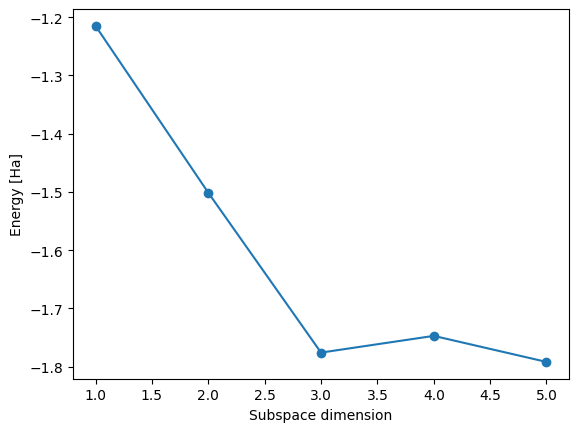

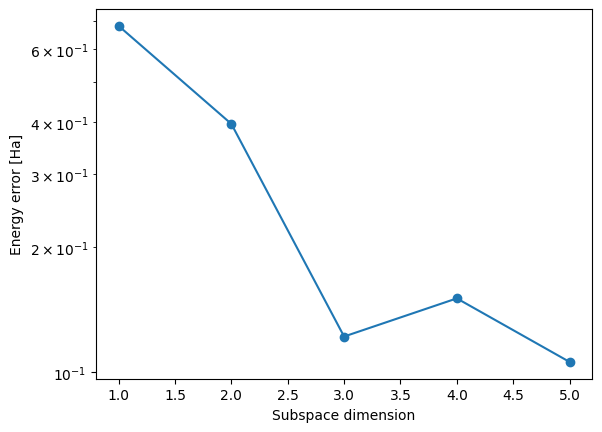

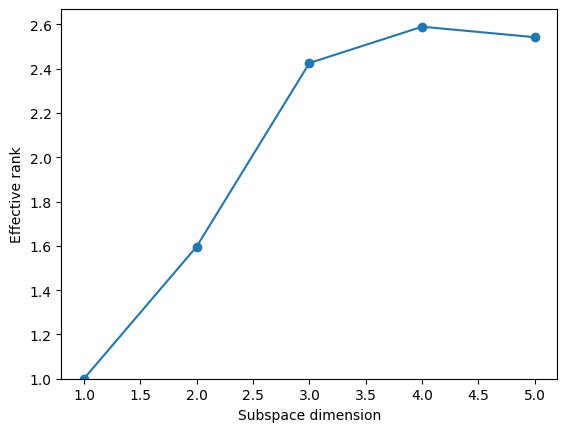

In [18]:
from scipy.linalg import eigvals
import matplotlib.pyplot as plt
from openfermion import QubitOperator

energies = []
errors = []
ranks = []
dims = []

s_matrix = np.zeros((5, 5), dtype=complex)
h_matrix = np.zeros((5, 5), dtype=complex)

id_qubit = QubitOperator('')

for n_dim in range(1, 6):

    for i in range(n_dim):
        j = n_dim - 1

        # get circuits that implement states
        circuit_i = qc.assign_parameters([i+dt])
        circuit_j = qc.assign_parameters([j+dt])

        h_matrix[i, j] = (get_matrix_element(circuit_i, circuit_j, ha_qubit, imaginary_part=False) +
                          1j * get_matrix_element(circuit_i, circuit_j, ha_qubit, imaginary_part=True))

        s_matrix[i, j] = (get_matrix_element(circuit_i, circuit_j, id_qubit, imaginary_part=False) +
                          1j * get_matrix_element(circuit_i, circuit_j, id_qubit, imaginary_part=True))

        s_matrix[j, i] = s_matrix[i, j].conj()
        h_matrix[j, i] = h_matrix[i, j].conj()

    # symmetrize matrices
    for i in range(n_dim):
        s_matrix[i, i] = 1.0
        h_matrix[i, i] = h_matrix[i, i].real

    ranks.append(effective_rank(s_matrix))

    h_matrix_r, s_matrix_r = get_regularized_matrices(h_matrix, s_matrix)
    vals = min(eigvals(h_matrix_r, s_matrix_r))
    energies.append(vals.real)
    errors.append(vals.real - fci_energy)
    dims.append(n_dim)
    print(energies)

print('Converged energy: ', energies[-1])
plt.plot(dims, energies, '-o')
plt.xlabel('Subspace dimension')
plt.ylabel('Energy [Ha]')
plt.show()

plt.plot(dims, errors, '-o')
plt.yscale('log')
plt.xlabel('Subspace dimension')
plt.ylabel('Energy error [Ha]')
plt.show()

plt.plot(dims, ranks, '-o')
plt.xlabel('Subspace dimension')
plt.ylabel('Effective rank')
plt.ylim(1, None)
plt.show()

- Change the Hamiltonian ooperator
- Compress hamiltonian operator for time evolution
- Effective Hamiltonian (active space, frozen core)